#Punto A

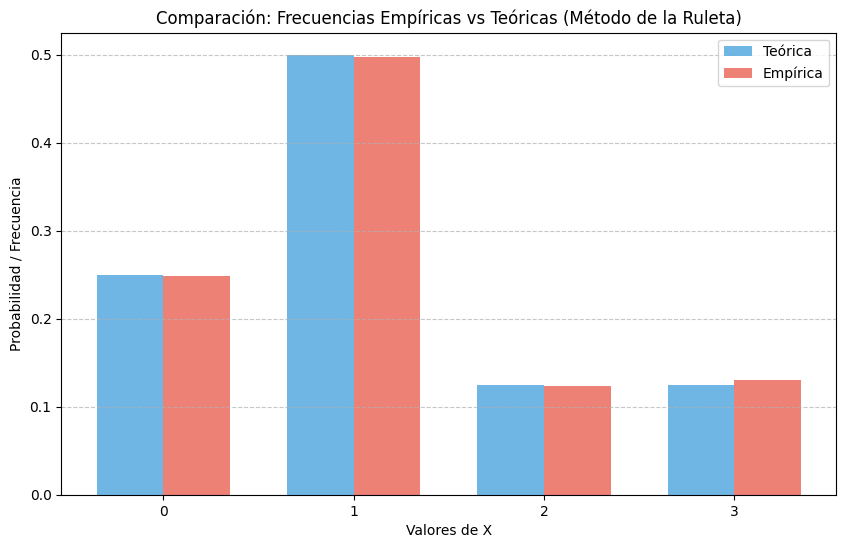

Resultados tras 10000 muestras:
Valor 0: Teórica = 0.2500 | Empírica = 0.2483 | Error = 0.0017
Valor 1: Teórica = 0.5000 | Empírica = 0.4978 | Error = 0.0022
Valor 2: Teórica = 0.1250 | Empírica = 0.1236 | Error = 0.0014
Valor 3: Teórica = 0.1250 | Empírica = 0.1303 | Error = 0.0053


In [3]:
import numpy as np
import matplotlib.pyplot as plt

#Configuración de parámetros
n_muestras = 10000
valores_x = [0, 1, 2, 3]
probabilidades_teoricas = [1/4, 1/2, 1/8, 1/8]

#Cálculo de probabilidades acumuladas ]
prob_acumuladas = np.cumsum(probabilidades_teoricas)


# Generamos la muestra con 10,000 números uniformes U(0,1)
u = np.random.rand(n_muestras)
muestras = []

for valor_u in u:
    if valor_u < prob_acumuladas[0]:
        muestras.append(0)
    elif valor_u < prob_acumuladas[1]:
        muestras.append(1)
    elif valor_u < prob_acumuladas[2]:
        muestras.append(2)
    else:
        muestras.append(3)

#Cálculamos las frecuencias empíricas
valores, conteos = np.unique(muestras, return_counts=True)
frecuencias_empiricas = conteos / n_muestras

# Hacemos la visualización y Comparación
plt.figure(figsize=(10, 6))
x = np.arange(len(valores_x))
width = 0.35

plt.bar(x - width/2, probabilidades_teoricas, width, label='Teórica', color='#3498db', alpha=0.7)
plt.bar(x + width/2, frecuencias_empiricas, width, label='Empírica', color='#e74c3c', alpha=0.7)

plt.xlabel('Valores de X')
plt.ylabel('Probabilidad / Frecuencia')
plt.title('Comparación: Frecuencias Empíricas vs Teóricas (Método de la Ruleta)')
plt.xticks(x, valores_x)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

#Mostramos los resultados numéricos
print(f"Resultados tras {n_muestras} muestras:")
for v, p_t, f_e in zip(valores_x, probabilidades_teoricas, frecuencias_empiricas):
    print(f"Valor {v}: Teórica = {p_t:.4f} | Empírica = {f_e:.4f} | Error = {abs(p_t - f_e):.4f}")

#Punto B - Ejer 1

In [ ]:
import numpy as np

# Declaramos los parámetro
n_bernoulli = 20000
p_teorico = 0.3

# Generamos U - Unif(0, 1). Si U < p, entonces X = 1 (éxito)
u_bernoulli = np.random.rand(n_bernoulli)
datos_bernoulli = (u_bernoulli < p_teorico).astype(int)

# 3. Cálculo de resultados
exitos_totales = np.sum(datos_bernoulli)
proporcion_empirica = exitos_totales / n_bernoulli

# 4. Mostramos resultados
print(f"--- Resultados Distribución Bernoulli ---")
print(f"Muestras generadas: {n_bernoulli}")
print(f"Probabilidad teórica (p): {p_teorico}")
print(f"Proporción empírica de éxitos: {proporcion_empirica:.4f}")
print(f"Diferencia absoluta: {abs(p_teorico - proporcion_empirica):.6f}")

#Punto B - Ejer 2

In [ ]:
import numpy as np

# Tambien declaramos parámetro
n_poisson = 50000
lambda_teo = 3

# 2. Generamos los datos
datos_poisson = np.random.poisson(lambda_teo, n_poisson)

# 3. Cálculo de métricas empíricas
media_empirica = np.mean(datos_poisson)
varianza_empirica = np.var(datos_poisson)

# 4. Mostramos comparaciones
print(f"--- Resultados Distribución Poisson ---")
print(f"Muestras generadas: {n_poisson}")
print(f"Parámetro Lambda (λ): {lambda_teo}")
print(f"Media Empírica: {media_empirica:.4f} (Teórica: {lambda_teo})")
print(f"Varianza Empírica: {varianza_empirica:.4f} (Teórica: {lambda_teo})")
print(f"Diferencia en Media: {abs(lambda_teo - media_empirica):.6f}")
print(f"Diferencia en Varianza: {abs(lambda_teo - varianza_empirica):.6f}")

#Punto C

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#Parámetros
n_uniforme = 20000
a, b = 2, 5

#Generación por transformada inversa
u = np.random.rand(n_uniforme)
datos_uniforme = a + (b - a) * u

# Hacemos la visualización
plt.figure(figsize=(10, 6))

# Histograma empírico
plt.hist(datos_uniforme, bins=40, density=True, color='skyblue', edgecolor='white', alpha=0.7, label='Histograma Empírico')


x_teorico = np.linspace(a - 0.5, b + 0.5, 1000)
pdf_teorica = np.where((x_teorico >= a) & (x_teorico <= b), 1/(b-a), 0)
plt.plot(x_teorico, pdf_teorica, color='red', lw=3, label='Densidad Teórica')

plt.title(f'Distribución Uniforme ({a}, {b}) - 20,000 muestras')
plt.xlabel('Valor de X')
plt.ylabel('Densidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Punto D

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#Parámetros
n_exp = 30000
alpha = 1.2

#Generación por transformada inversa
u = np.random.rand(n_exp)
datos_exponencial = -(1/alpha) * np.log(1 - u)

# Visualización
plt.figure(figsize=(10, 6))

# Histograma empírico
plt.hist(datos_exponencial, bins=60, density=True, color='mediumpurple', edgecolor='white', alpha=0.7, label='Histograma Empírico')

# Densidad teórica
x_teorico = np.linspace(0, np.max(datos_exponencial), 1000)
pdf_teorica = alpha * np.exp(-alpha * x_teorico)
plt.plot(x_teorico, pdf_teorica, color='darkred', lw=3, label='PDF Teórica')

plt.title(f'Distribución Exponencial (α={alpha}) - 30,000 muestras')
plt.xlabel('Valor de X')
plt.ylabel('Densidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Punto E

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

#Hallamos parámetros
n_norm = 30000
mu = 650
sigma = 50

#Generamos usando el método Box-Muller
u1 = np.random.rand(n_norm // 2)
u2 = np.random.rand(n_norm // 2)

#Transformamos de Box-Muller para obtener Z
z0 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
z1 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)


z = np.concatenate((z0, z1))

#Ajustamos a la media y desviación estándar deseada: X = mu + sigma * Z
datos_normal = mu + sigma * z

#Visualización
plt.figure(figsize=(10, 6))

#Histograma empírico
plt.hist(datos_normal, bins=70, density=True, color='royalblue', edgecolor='white', alpha=0.7, label='Histograma Empírico')

#Curva teórica
x_plot = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
plt.plot(x_plot, stats.norm.pdf(x_plot, mu, sigma), color='red', lw=3, label='PDF Teórica (Normal)')

plt.title(f'Distribución Normal ($\mu$={mu}, $\sigma$={sigma}) - Método Box-Muller')
plt.xlabel('Valor de X')
plt.ylabel('Densidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Punto F

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_tri = 20000
a = 5000
b = 7800
c = 8000

# En numpy.random.triangular los parámetros son (left, mode, right, size)
datos_triangular = np.random.triangular(a, b, c, n_tri)

#Visualización
plt.figure(figsize=(10, 6))

#Histograma empírico
plt.hist(datos_triangular, bins=60, density=True, color='teal', edgecolor='white', alpha=0.7, label='Histograma Empírico')

#Hacemos esto para dinujar líneas para identificar los parámetros
plt.axvline(a, color='red', linestyle='--', label=f'Mínimo (a={a})')
plt.axvline(b, color='gold', linestyle='--', label=f'Moda (b={b})')
plt.axvline(c, color='red', linestyle='--', label=f'Máximo (c={c})')

plt.title(f'Distribución Triangular ({a}, {b}, {c})')
plt.xlabel('Valor de X')
plt.ylabel('Densidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()